# AI651 — Assignment 2 — Question 2



In [2]:

import time, random, json, shutil
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import MovingMNIST
from tqdm.auto import tqdm
from IPython.display import display

SAVE_TO_DRIVE = True
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/DL4STG_PA2/pa2_outputs')
else:
    OUT = Path('pa2_outputs')
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH, EPOCHS = 32, 30
TRAIN_IDS, VAL_IDS, TEST_IDS = range(8000), range(8000, 9000), range(9000, 10000)
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def figure_save(filename):
    plt.savefig(OUT / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

def save_table(rows, filename):
    frame = pd.DataFrame(rows)
    frame.to_csv(OUT / filename, index=False)
    display(frame)
    return frame

raw = MovingMNIST(root='data', split=None, download=True)
assert len(raw) == 10000

def video_at(index):
    v = raw[index]
    if isinstance(v, (tuple, list)):
        v = v[0]
    v = torch.as_tensor(v)
    assert v.shape == (20, 1, 64, 64), v.shape
    return v.float().div(255)

G = [(a, mirror) for mirror in (False, True) for a in range(4)]
M, R = (0, True), (1, False)

def transform(x, element):
    a, mirror = element
    x = torch.rot90(x, a, dims=(-2, -1))
    return x.flip(-1) if mirror else x

def inverse(element):
    a, mirror = element
    return element if mirror else ((-a) % 4, False)

def window(video, speed=1, start=1):
    indices = list(range(start - 1, 20, speed))
    return video[indices[:5]], video[indices[5:10]]

def allowed_starts(speed, augmented):
    return {1: 14, 2: 8, 3: 2}[speed] if augmented else 11

class VideoWindows(Dataset):
    def __init__(self, ids, training=False, speed_aug=False, symmetry_aug=False, speed=1):
        self.ids = list(ids)
        self.training, self.speed_aug = training, speed_aug
        self.symmetry_aug, self.speed = symmetry_aug, speed

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        v = video_at(self.ids[i])
        speed = random.choice((1, 2, 3)) if self.training and self.speed_aug else self.speed
        start = random.randint(1, allowed_starts(speed, self.speed_aug)) if self.training else 1
        x, y = window(v, speed, start)
        if self.training and self.symmetry_aug:
            g = random.choice(G)
            x, y = transform(x, g), transform(y, g)
        mask = torch.zeros(5, dtype=torch.bool)
        mask[:len(y)] = True
        targets = torch.zeros_like(x)
        targets[:len(y)] = y
        return x, targets, mask

def make_loader(ids, training=False, speed_aug=False, symmetry_aug=False, speed=1):
    ds = VideoWindows(ids, training, speed_aug, symmetry_aug, speed)
    return DataLoader(ds, batch_size=BATCH, shuffle=training, num_workers=0,
                      pin_memory=DEVICE.type == 'cuda')

Mounted at /content/drive
Device: cuda | PyTorch: 2.11.0+cu130


100%|██████████| 819M/819M [00:20<00:00, 39.3MB/s]


## Table 1 — Transformation and window checks

In [3]:
set_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros_like(x)
p[7, 0, 10, 20] = 1
filled = torch.arange(1, 21).float()[:, None, None, None].expand(20, 1, 64, 64)
values = [
    (transform(transform(x, M), M) - x).abs().max().item(),
    (transform(x, (4, False)) - x).abs().max().item(),
    (transform(transform(transform(x, M), R), M) - transform(x, (3, False))).abs().max().item(),
    tuple(torch.nonzero(transform(p, M))[0][[0, 2, 3]].tolist()),
    tuple(torch.nonzero(transform(p, R))[0][[0, 2, 3]].tolist()),
]
for k in (1, 2, 3):
    a, b = window(filled, k)
    values.append((a[:, 0, 0, 0].int().tolist(), b[:, 0, 0, 0].int().tolist()))
expected = [
    0, 0, 0, (7, 10, 43), (7, 43, 10),
    ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]),
    ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]),
    ([1, 4, 7, 10, 13], [16, 19]),
]
assert values == expected
checks = ['(a) M(M(x))', '(b) R^4(x)', '(c) MRM(x) = R^-1(x)',
          '(d) pixel of M(p)', '(e) pixel of R(p)',
          '(f) 1x frames', '(g) 2x frames', '(h) 3x frames']
table1 = save_table([{'Check': c, 'Expected': str(e), 'Observed': str(v),
                      'Pass': v == e} for c, e, v in zip(checks, expected, values)], 'table1.csv')
assert table1['Pass'].all()

,Check,Expected,Observed,Pass
0,(a) M(M(x)),0,0.0,True
1,(b) R^4(x),0,0.0,True
2,(c) MRM(x) = R^-1(x),0,0.0,True
3,(d) pixel of M(p),"(7, 10, 43)","(7, 10, 43)",True
4,(e) pixel of R(p),"(7, 43, 10)","(7, 43, 10)",True
5,(f) 1x frames,"([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])","([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])",True
6,(g) 2x frames,"([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])","([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])",True
7,(h) 3x frames,"([1, 4, 7, 10, 13], [16, 19])","([1, 4, 7, 10, 13], [16, 19])",True


Optical flow:   0%|          | 0/50 [00:00<?, ?it/s]

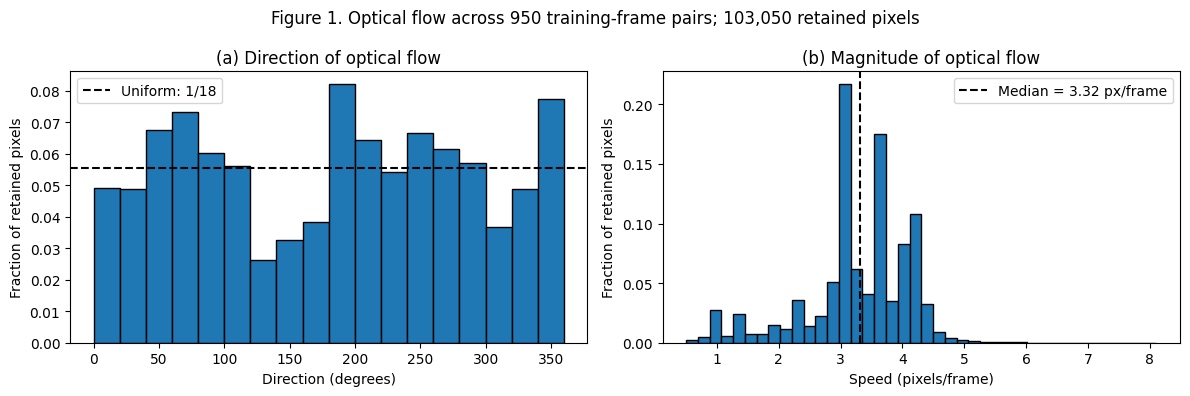

Median speed: 3.32; 2x: 6.64; 3x: 9.95


In [4]:
directions, speeds = [], []
for index in tqdm(range(50), desc='Optical flow'):
    frames = video_at(index).numpy()[:, 0]
    for s in range(19):
        prev = np.rint(frames[s] * 255).astype(np.uint8)
        nxt = np.rint(frames[s + 1] * 255).astype(np.uint8)
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        magnitude = np.hypot(dx, dy)
        keep = (frames[s] > 0.2) & (frames[s + 1] > 0.2) & (magnitude > 0.5)
        directions.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360)
        speeds.append(magnitude[keep])
directions = np.concatenate(directions)
speeds = np.concatenate(speeds)
median_speed = np.median(speeds)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(directions, bins=np.arange(0, 361, 20),
             weights=np.ones(len(directions)) / len(directions), edgecolor='black')
axes[0].axhline(1 / 18, linestyle='--', color='black', label='Uniform: 1/18')
axes[0].set(xlabel='Direction (degrees)', ylabel='Fraction of retained pixels',
            title='(a) Direction of optical flow')
axes[0].legend()
axes[1].hist(speeds, bins=40, weights=np.ones(len(speeds)) / len(speeds), edgecolor='black')
axes[1].axvline(median_speed, linestyle='--', color='black',
                label=f'Median = {median_speed:.3g} px/frame')
axes[1].set(xlabel='Speed (pixels/frame)', ylabel='Fraction of retained pixels',
            title='(b) Magnitude of optical flow')
axes[1].legend()
fig.suptitle(f'Figure 1. Optical flow across 950 training-frame pairs; '
             f'{len(speeds):,} retained pixels')
fig.tight_layout()
figure_save('figure1.png')
(OUT / 'figure1_values.json').write_text(json.dumps({
    'retained_pixels': int(len(speeds)), 'median_speed': float(median_speed),
    'approx_2x': float(2 * median_speed), 'approx_3x': float(3 * median_speed)
}, indent=2))
print(f'Median speed: {median_speed:.3g}; 2x: {2 * median_speed:.3g}; 3x: {3 * median_speed:.3g}')

In [5]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden=64, dilation=1):
        super().__init__()
        self.gates = nn.Conv2d(in_channels + hidden, 4 * hidden, 3,
                               padding=dilation, dilation=dilation, bias=True)

    def forward(self, x, h, c):
        i, f, o, g = self.gates(torch.cat((x, h), dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ConvLSTM(nn.Module):
    def __init__(self, dilation2=1):
        super().__init__()
        self.cell1 = ConvLSTMCell(16, 64, dilation=1)
        self.cell2 = ConvLSTMCell(64, 64, dilation=dilation2)
        self.head = nn.Conv2d(64, 16, 1, bias=True)

    def forward(self, x):
        batch = x.shape[0]
        h1 = x.new_zeros(batch, 64, 16, 16)
        c1 = torch.zeros_like(h1)
        h2, c2 = torch.zeros_like(h1), torch.zeros_like(h1)
        predictions = []
        for step in range(9):
            frame = x[:, step] if step < 5 else prediction
            folded = F.pixel_unshuffle(frame, 4)
            h1, c1 = self.cell1(folded, h1, c1)
            h2, c2 = self.cell2(h1, h2, c2)
            prediction = torch.sigmoid(F.pixel_shuffle(self.head(h2), 4))
            if step >= 4:
                predictions.append(prediction)
        return torch.stack(predictions, 1)

class ModelD(ConvLSTM):
    def __init__(self):
        super().__init__(dilation2=2)

class Reference(nn.Module):
    def __init__(self, method):
        super().__init__()
        self.method = method

    def forward(self, x):
        return torch.zeros_like(x) if self.method == 'Blank' else x[:, -1:].expand_as(x)

def parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

assert parameters(ConvLSTM()) == 480784
assert parameters(ModelD()) <= 721176
assert ConvLSTM()(torch.zeros(1, 5, 1, 64, 64)).shape == (1, 5, 1, 64, 64)
assert ModelD()(torch.zeros(1, 5, 1, 64, 64)).shape == (1, 5, 1, 64, 64)
print('A/B/C parameters:', parameters(ConvLSTM()), '| reach: 8 pixels')
print('D parameters:', parameters(ModelD()), '| reach: 12 pixels')

A/B/C parameters: 480784 | reach: 8 pixels
D parameters: 480784 | reach: 12 pixels


In [6]:
def rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(),
            'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def restore_rng(s):
    random.setstate(s['python'])
    np.random.set_state(s['numpy'])
    torch.set_rng_state(s['torch'])
    if s['cuda'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(s['cuda'])

def checkpoint_read(path):
    return torch.load(path, map_location='cpu', weights_only=False)

def train_model(name, factory, seed, speed_aug=False, symmetry_aug=False):
    path = OUT / f'{name}_seed{seed}.pt'
    set_seed(seed)
    model = factory().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    epoch_times, epoch_losses = [], []
    first_epoch = 0
    if path.exists():
        saved = checkpoint_read(path)
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        epoch_times, epoch_losses = saved['times'], saved['losses']
        first_epoch = saved['epoch']
        restore_rng(saved['rng'])
    train_loader = make_loader(TRAIN_IDS, training=True, speed_aug=speed_aug,
                               symmetry_aug=symmetry_aug)
    for epoch in range(first_epoch, EPOCHS):
        model.train()
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        started = time.perf_counter()
        total_loss = 0.0
        for x, target, mask in train_loader:
            x = x.to(DEVICE)
            target = target.to(DEVICE)
            mask = mask.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            predicted = model(x)
            frame_errors = (predicted - target).square().mean((2, 3, 4))
            loss = ((frame_errors * mask).sum(1) / mask.sum(1)).mean()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        epoch_times.append(time.perf_counter() - started)
        epoch_losses.append(total_loss / len(TRAIN_IDS))
        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'epoch': epoch + 1, 'times': epoch_times, 'losses': epoch_losses,
                    'rng': rng_state()}, path)
        print(f'{name} seed {seed}: epoch {epoch+1:02d}/{EPOCHS}, '
              f'loss={epoch_losses[-1]:.5f}, time={epoch_times[-1]:.1f}s')
    return model.eval(), float(np.mean(epoch_times)), epoch_losses

@torch.no_grad()
def get_predictions(model, speed=1):
    model.eval()
    x_all, y_all, mask_all, pred_all = [], [], [], []
    for x, y, mask in make_loader(TEST_IDS, speed=speed):
        pred = model(x.to(DEVICE)).cpu()
        x_all.append(x)
        y_all.append(y)
        mask_all.append(mask)
        pred_all.append(pred)
    return tuple(torch.cat(parts) for parts in (x_all, y_all, mask_all, pred_all))

def horizon_mse(prediction, true):
    return (prediction - true).square().mean((2, 3, 4))

def scoring(prediction, true, mask):
    errors = horizon_mse(prediction, true)
    result = {}
    for h in range(5):
        good = mask[:, h]
        result[f'MSE{h+1}'] = float(errors[good, h].mean()) if good.any() else np.nan
    for length in (2, 5):
        use = mask[:, :length]
        result[f'E{length}'] = float(((errors[:, :length] * use).sum(1) / use.sum(1)).mean())
    return result

@torch.no_grad()
def transformed_outputs(model, x, g):
    model.eval()
    outputs = []
    for part in x.split(BATCH):
        outputs.append(model(transform(part.to(DEVICE), g)).cpu())
    return torch.cat(outputs)

def spatial_scores(model, x, true, prediction):
    result, gaps = {}, {}
    for g, label in ((M, 'M'), (R, 'R')):
        p_transform = transformed_outputs(model, x, g)
        gap = horizon_mse(p_transform, transform(prediction, g)).mean(1)
        err = horizon_mse(p_transform, transform(true, g)).mean(1)
        result[f'C{label}'] = float(gap.mean())
        result[f'E{label}'] = float(err.mean())
        gaps[label] = gap
    return result, gaps

@torch.no_grad()
def prediction_time(model):
    model.eval()
    batches = [x.to(DEVICE) for x, _, _ in make_loader(TEST_IDS)]
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for x in batches:
        model(x)
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    return time.perf_counter() - t0

def model_scores(model):
    x, y, mask, pred = get_predictions(model, 1)
    metrics = scoring(pred, y, mask)
    spatial, _ = spatial_scores(model, x, y, pred)
    metrics.update(spatial)
    for k in (2, 3):
        xk, yk, mk, pk = get_predictions(model, k)
        metrics[f'E2_{k}x'] = scoring(pk, yk, mk)['E2']
    metrics['Parameters'] = parameters(model)
    metrics['Inference_s'] = prediction_time(model)
    return metrics

def two_seeds(a, b):
    return {key: f'{np.mean([a[key], b[key]]):.3g} '
                 f'({a[key]:.3g}, {b[key]:.3g})' for key in a}

class Symmetrised(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return torch.stack([transform(self.model(transform(x, g)), inverse(g))
                            for g in G], 0).mean(0)

models, times, losses = {}, {}, {}
for name, factory, speed_aug, symmetry_aug in (
    ('A', ConvLSTM, False, False),
    ('B', ConvLSTM, False, True),
    ('C', ConvLSTM, True, False),
    ('D', ModelD, True, False),
):
    for seed in (0, 1):
        models[name, seed], times[name, seed], losses[name, seed] = train_model(
            name, factory, seed, speed_aug=speed_aug, symmetry_aug=symmetry_aug)

A seed 0: epoch 01/30, loss=0.04614, time=9.9s
A seed 0: epoch 02/30, loss=0.03969, time=7.4s
A seed 0: epoch 03/30, loss=0.03866, time=7.5s
A seed 0: epoch 04/30, loss=0.03713, time=7.5s
A seed 0: epoch 05/30, loss=0.03523, time=7.5s
A seed 0: epoch 06/30, loss=0.03341, time=7.4s
A seed 0: epoch 07/30, loss=0.03220, time=7.4s
A seed 0: epoch 08/30, loss=0.03113, time=7.4s
A seed 0: epoch 09/30, loss=0.03041, time=7.5s
A seed 0: epoch 10/30, loss=0.02979, time=7.4s
A seed 0: epoch 11/30, loss=0.02946, time=7.5s
A seed 0: epoch 12/30, loss=0.02899, time=7.4s
A seed 0: epoch 13/30, loss=0.02854, time=7.5s
A seed 0: epoch 14/30, loss=0.02817, time=7.5s
A seed 0: epoch 15/30, loss=0.02772, time=7.4s
A seed 0: epoch 16/30, loss=0.02745, time=7.5s
A seed 0: epoch 17/30, loss=0.02697, time=7.6s
A seed 0: epoch 18/30, loss=0.02666, time=7.5s
A seed 0: epoch 19/30, loss=0.02618, time=7.5s
A seed 0: epoch 20/30, loss=0.02597, time=7.5s
A seed 0: epoch 21/30, loss=0.02564, time=7.5s
A seed 0: epo

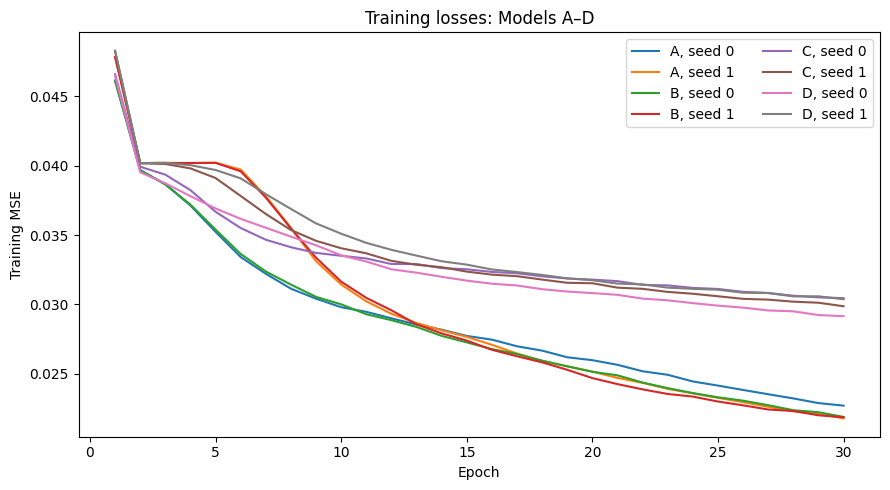

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for name in 'ABCD':
    for seed in (0, 1):
        ax.plot(range(1, EPOCHS + 1), losses[name, seed], label=f'{name}, seed {seed}')
ax.set(xlabel='Epoch', ylabel='Training MSE', title='Training losses: Models A–D')
ax.legend(ncol=2)
fig.tight_layout()
figure_save('training_curves.png')

In [8]:
table2_rows = []
for name in ('A', 'Blank', 'Copy-last'):
    candidates = [models['A', s] for s in (0, 1)] if name == 'A' else [Reference(name)]
    measured = []
    for model in candidates:
        _, y, mask, pred = get_predictions(model)
        result = scoring(pred, y, mask)
        result['Parameters'] = parameters(model)
        measured.append(result)
    table2_rows.append({'Model': name, **(two_seeds(*measured) if len(measured) == 2 else measured[0])})
table2 = save_table(table2_rows, 'table2.csv')

table3_rows = []
for name in ('A', 'Blank', 'Copy-last'):
    candidates = [models['A', s] for s in (0, 1)] if name == 'A' else [Reference(name)]
    measured = []
    for model in candidates:
        x, y, mask, pred = get_predictions(model)
        r = {'E5': scoring(pred, y, mask)['E5']}
        r.update(spatial_scores(model, x, y, pred)[0])
        measured.append(r)
    table3_rows.append({'Model': name, **(two_seeds(*measured) if len(measured) == 2 else measured[0])})
table3 = save_table(table3_rows, 'table3.csv')

table4_rows = []
for name in ('A', 'Copy-last'):
    candidates = [models['A', s] for s in (0, 1)] if name == 'A' else [Reference(name)]
    measured = []
    for model in candidates:
        r = {}
        for k in (1, 2, 3):
            _, y, mask, pred = get_predictions(model, k)
            m = scoring(pred, y, mask)
            r[f'E2_{k}x'] = m['E2']
            if k < 3:
                r[f'E5_{k}x'] = m['E5']
        measured.append(r)
    table4_rows.append({'Model': name, **(two_seeds(*measured) if len(measured) == 2 else measured[0])})
table4 = save_table(table4_rows, 'table4.csv')

table5_rows = []
for name in 'ABCD':
    measured = []
    for seed in (0, 1):
        r = model_scores(models[name, seed])
        r['Training_s_per_epoch'] = times[name, seed]
        measured.append(r)
    mean = two_seeds(*measured)
    table5_rows.append({'Model': name, **mean})
table5 = save_table(table5_rows, 'table5.csv')

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E2,E5,Parameters
0,A,"0.0171 (0.0177, 0.0166)","0.0206 (0.021, 0.0203)","0.023 (0.0232, 0.0228)","0.0247 (0.0248, 0.0247)","0.0264 (0.0263, 0.0265)","0.0189 (0.0194, 0.0184)","0.0224 (0.0226, 0.0222)","4.81e+05 (4.81e+05, 4.81e+05)"
1,Blank,0.04261,0.04257,0.042576,0.042532,0.04253,0.04259,0.042564,0
2,Copy-last,0.049164,0.06042,0.066889,0.070779,0.07316,0.054792,0.064082,0


,Model,E5,CM,EM,CR,ER
0,A,"0.0224 (0.0226, 0.0222)","0.00181 (0.00184, 0.00178)","0.0231 (0.0233, 0.0228)","0.00315 (0.00302, 0.00328)","0.0242 (0.0243, 0.0241)"
1,Blank,0.042564,0.0,0.042564,0.0,0.042564
2,Copy-last,0.064082,0.0,0.064082,0.0,0.064082


,Model,E2_1x,E5_1x,E2_2x,E5_2x,E2_3x
0,A,"0.0189 (0.0194, 0.0184)","0.0224 (0.0226, 0.0222)","0.0449 (0.0451, 0.0446)","0.049 (0.05, 0.048)","0.0525 (0.0538, 0.0513)"
1,Copy-last,0.054792,0.064082,0.066068,0.071882,0.070253


,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E2,E5,CM,EM,CR,ER,E2_2x,E2_3x,Parameters,Inference_s,Training_s_per_epoch
0,A,"0.0171 (0.0177, 0.0166)","0.0206 (0.021, 0.0203)","0.023 (0.0232, 0.0228)","0.0247 (0.0248, 0.0247)","0.0264 (0.0263, 0.0265)","0.0189 (0.0194, 0.0184)","0.0224 (0.0226, 0.0222)","0.00181 (0.00184, 0.00178)","0.0231 (0.0233, 0.0228)","0.00315 (0.00302, 0.00328)","0.0242 (0.0243, 0.0241)","0.0449 (0.0451, 0.0446)","0.0525 (0.0538, 0.0513)","4.81e+05 (4.81e+05, 4.81e+05)","0.182 (0.182, 0.181)","7.55 (7.57, 7.53)"
1,B,"0.0163 (0.0163, 0.0163)","0.0201 (0.0201, 0.0201)","0.0226 (0.0226, 0.0226)","0.0246 (0.0246, 0.0245)","0.0263 (0.0264, 0.0263)","0.0182 (0.0182, 0.0182)","0.022 (0.022, 0.022)","0.00155 (0.00167, 0.00143)","0.022 (0.0219, 0.0221)","0.00162 (0.00176, 0.00147)","0.0219 (0.022, 0.0219)","0.0444 (0.0445, 0.0442)","0.0496 (0.0493, 0.05)","4.81e+05 (4.81e+05, 4.81e+05)","0.184 (0.185, 0.184)","8.1 (8.12, 8.08)"
2,C,"0.0213 (0.0216, 0.021)","0.025 (0.0257, 0.0244)","0.0277 (0.0286, 0.0268)","0.0297 (0.0306, 0.0288)","0.0315 (0.0324, 0.0306)","0.0232 (0.0236, 0.0227)","0.027 (0.0278, 0.0263)","0.00114 (0.00121, 0.00108)","0.0273 (0.028, 0.0266)","0.00259 (0.00265, 0.00253)","0.0283 (0.0289, 0.0276)","0.0287 (0.0289, 0.0285)","0.0335 (0.0336, 0.0334)","4.81e+05 (4.81e+05, 4.81e+05)","0.185 (0.185, 0.185)","7.46 (7.45, 7.46)"
3,D,"0.0227 (0.022, 0.0234)","0.0254 (0.0249, 0.0259)","0.0272 (0.0267, 0.0277)","0.0288 (0.0282, 0.0293)","0.0303 (0.0296, 0.0309)","0.024 (0.0234, 0.0246)","0.0269 (0.0263, 0.0274)","0.000819 (0.00107, 0.000566)","0.027 (0.0265, 0.0276)","0.00201 (0.00245, 0.00157)","0.028 (0.0275, 0.0285)","0.0284 (0.0277, 0.0291)","0.0323 (0.0317, 0.0329)","4.81e+05 (4.81e+05, 4.81e+05)","0.189 (0.189, 0.189)","7.49 (7.48, 7.51)"


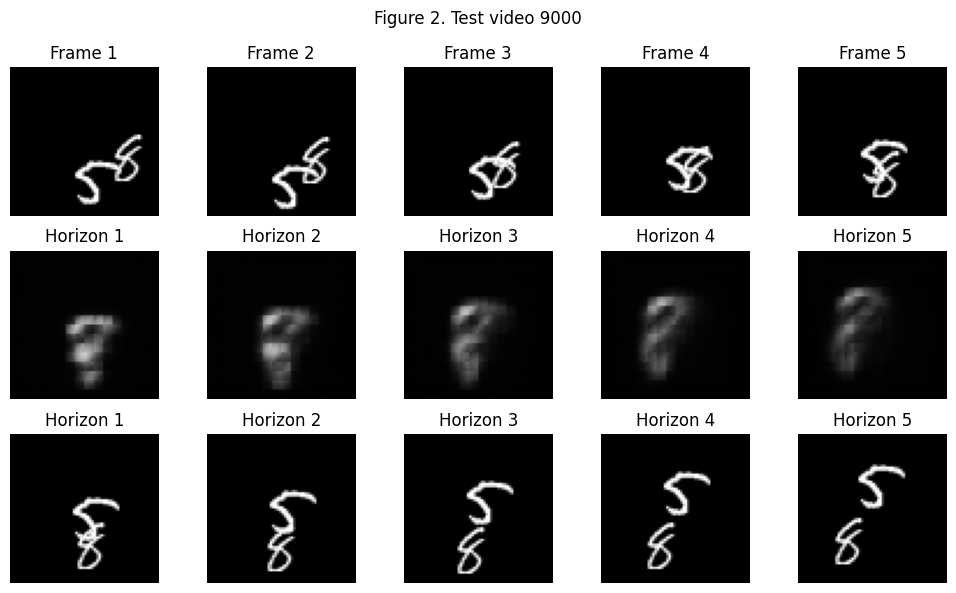

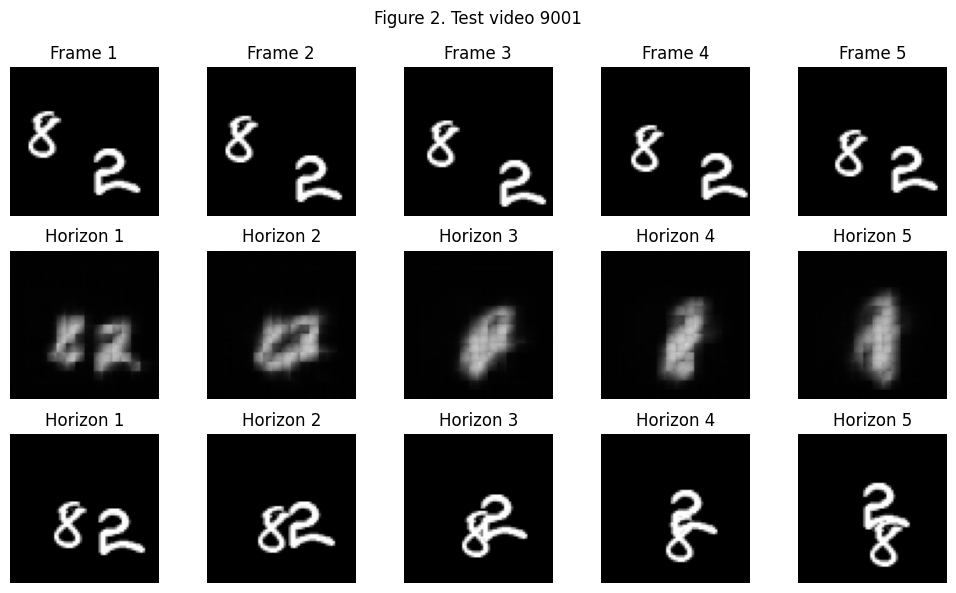

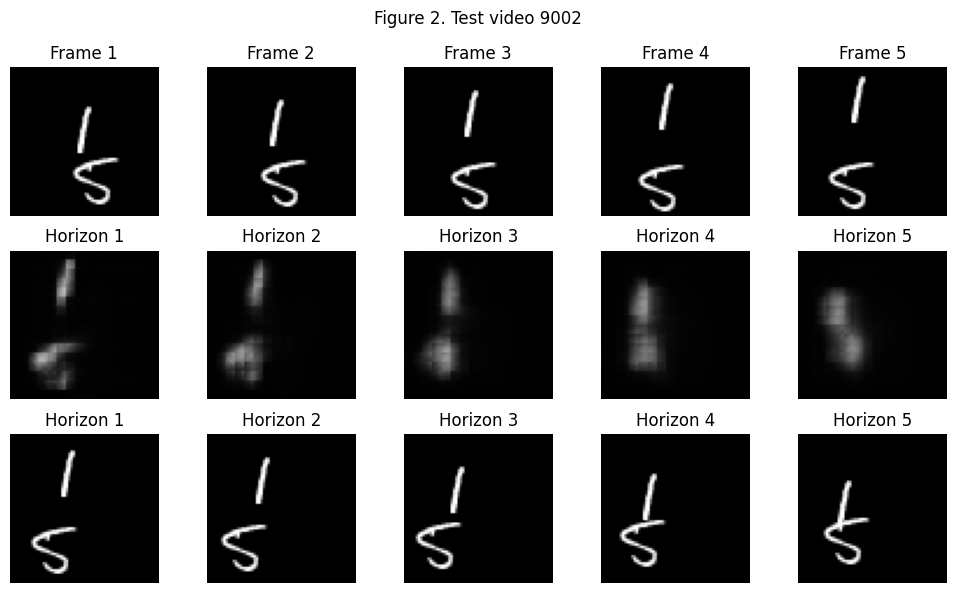

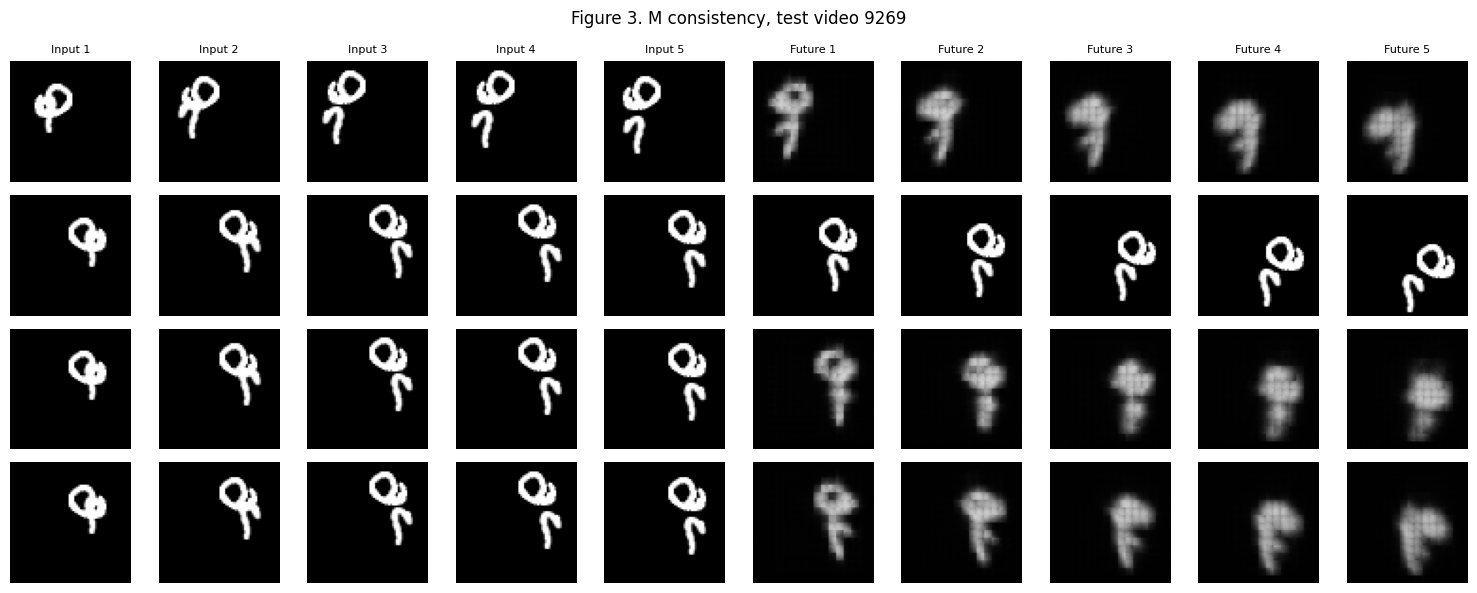

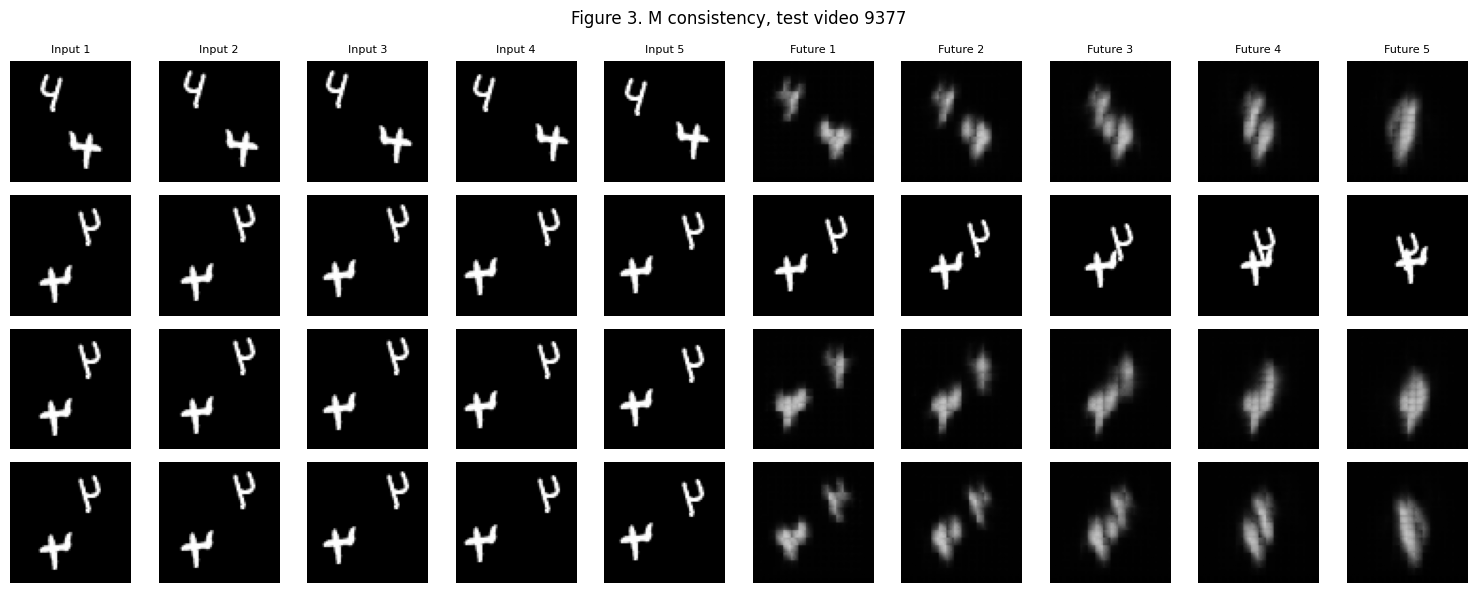

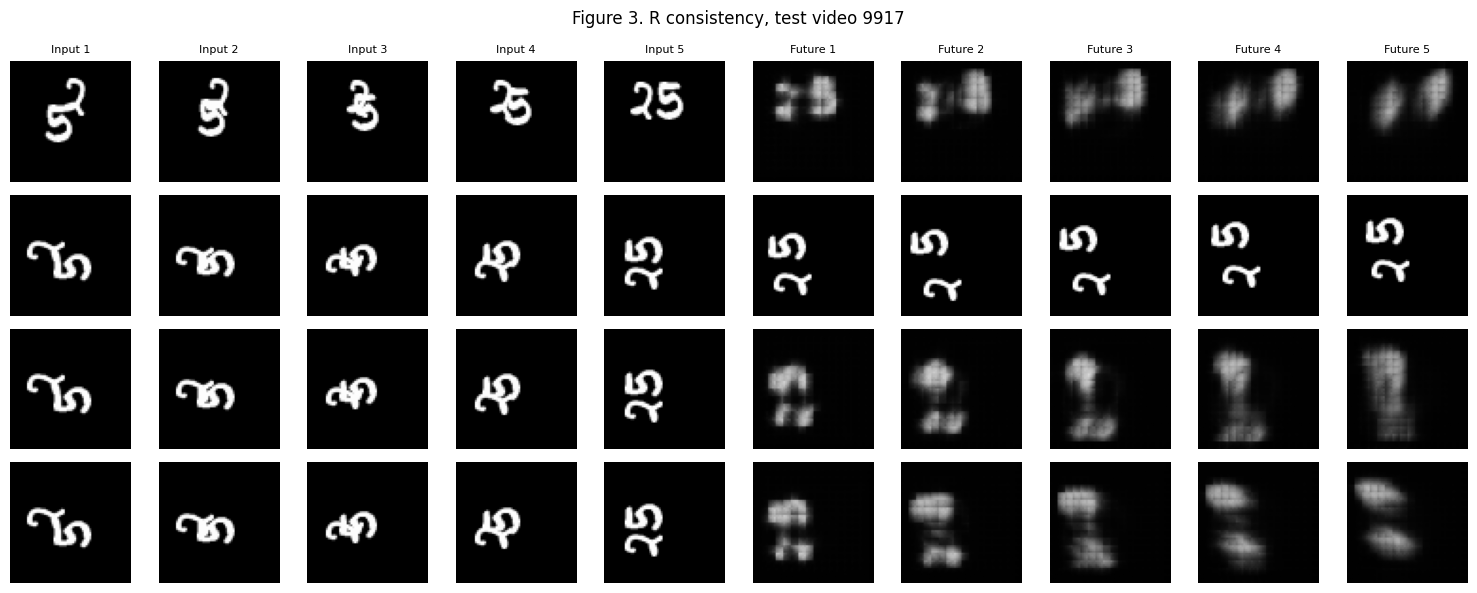

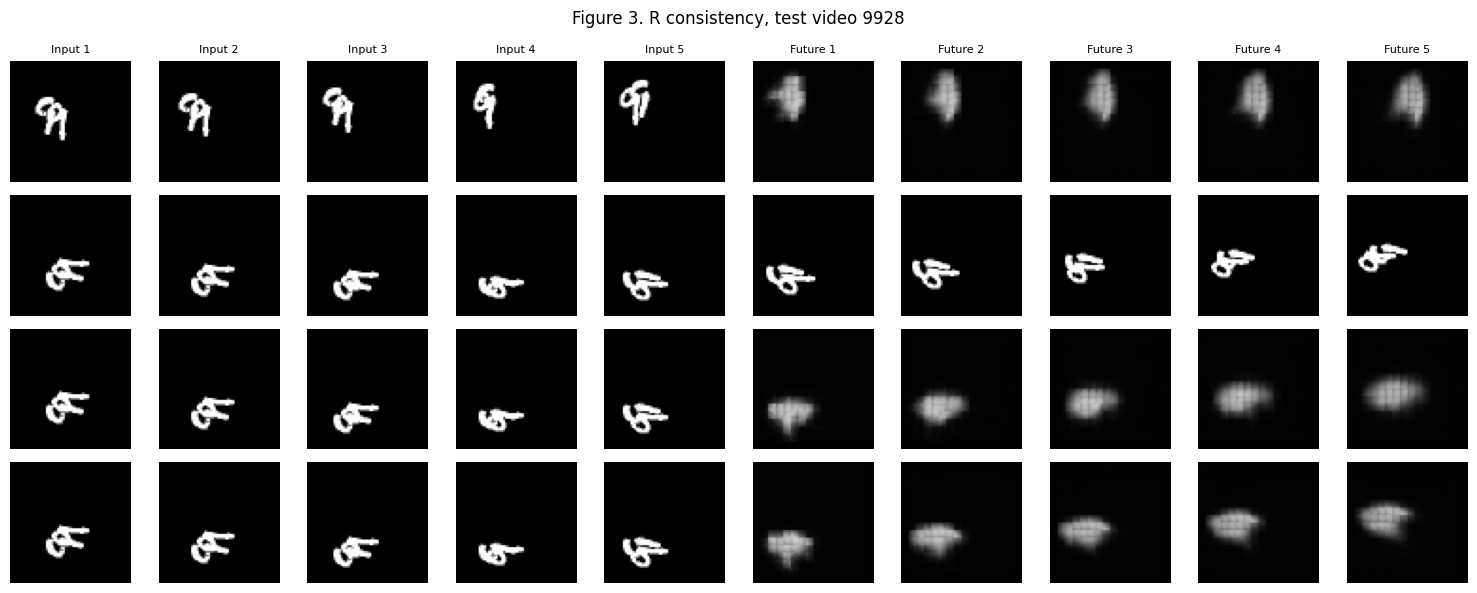

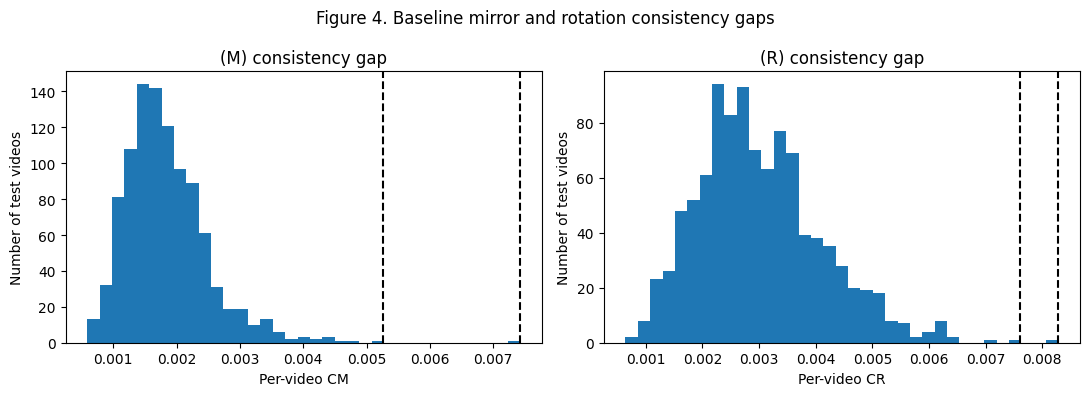

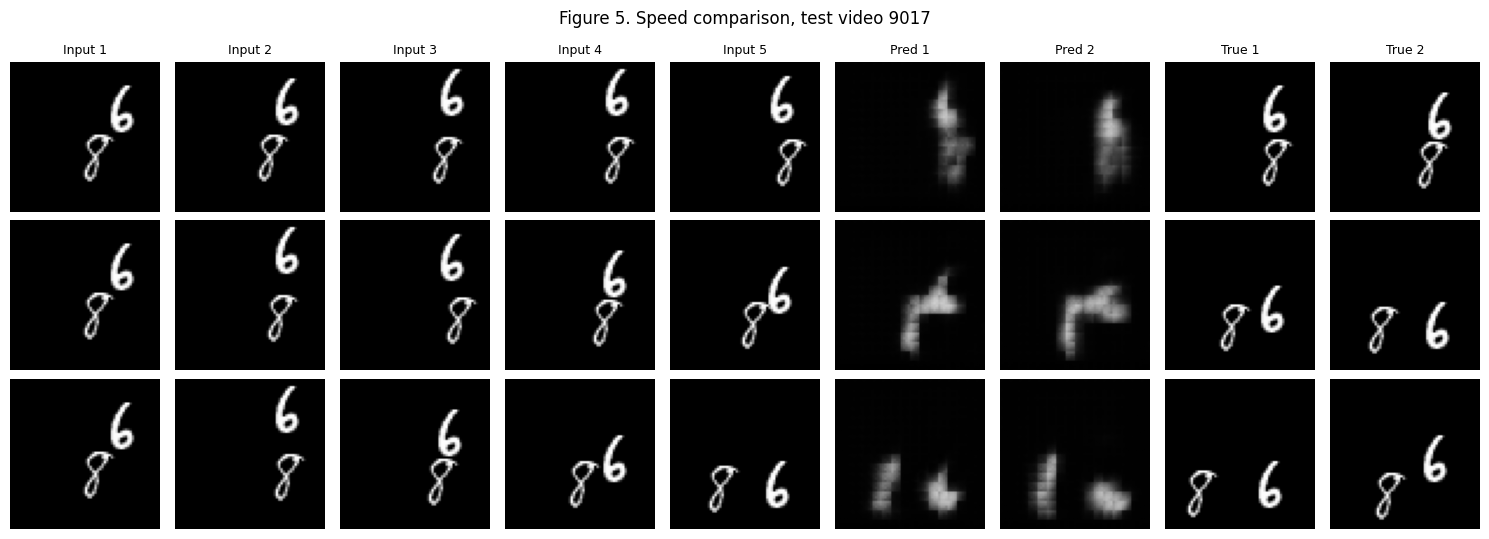

In [9]:
def components(frame):
    image = (frame[0].numpy() > 0.2).astype(np.uint8)
    count, _, stats, _ = cv2.connectedComponentsWithStats(image, connectivity=8)
    return [tuple(row) for row in stats[1:] if row[4] >= 12]

def select_figure2(x, y):
    overlap = []
    for i in range(len(x)):
        all_frames = torch.cat([x[i], y[i]], 0)
        count = [len(components(f)) for f in all_frames]
        if any(c >= 2 for c in count) and any(c == 1 for c in count):
            overlap.append(i)
    assert overlap, 'Could not identify a candidate with overlapping digits'
    ids = [overlap[0]]
    ids += [i for i in range(len(x)) if i not in ids][:2]
    return ids

def select_figure5():
    truth_frames = (6, 7, 11, 13, 16, 19)
    for i in range(1000):
        video = video_at(9000 + i)
        if all(len(components(video[frame-1])) == 2 for frame in truth_frames):
            return i
    raise RuntimeError('No suitable Figure 5 test video found')

def strip(x, predicted, target, filename, index):
    fig, axes = plt.subplots(3, 5, figsize=(10, 6))
    for row, seq in enumerate((x, predicted, target)):
        for j in range(5):
            axes[row, j].imshow(seq[j, 0], cmap='gray', vmin=0, vmax=1)
            axes[row, j].axis('off')
            if row == 0:
                axes[row, j].set_title(f'Frame {j+1}')
            else:
                axes[row, j].set_title(f'Horizon {j+1}')
        axes[row, 0].set_ylabel(('Input', 'Prediction', 'Ground truth')[row])
    fig.suptitle(f'Figure 2. Test video {9000+index}')
    fig.tight_layout()
    figure_save(filename)

def four_rows(x, y, pred, pred_t, g):
    tx = transform(x, g)
    return ((x, pred), (tx, transform(y, g)),
            (tx, pred_t), (tx, transform(pred, g)))

def panel_image(x, y, pred, pred_t, g, filename, title):
    fig, axes = plt.subplots(4, 10, figsize=(15, 6))
    names = ('X / f(X)', 'T(X) / T(Y)', 'T(X) / f(T(X))', 'T(X) / T(f(X))')
    for row, (inputs, futures) in enumerate(four_rows(x, y, pred, pred_t, g)):
        for j, frame in enumerate(torch.cat((inputs, futures))):
            axes[row, j].imshow(frame[0], cmap='gray', vmin=0, vmax=1)
            axes[row, j].axis('off')
        axes[row, 0].set_ylabel(names[row], fontsize=8)
    for j in range(10):
        axes[0, j].set_title(f'Input {j+1}' if j < 5 else f'Future {j-4}', fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    figure_save(filename)

def panel_gif(x, y, pred, pred_t, g, filename):
    panels = four_rows(x, y, pred, pred_t, g)
    frames = []
    for horizon in range(5):
        canvas = Image.new('RGB', (10*64, 4*64), 'black')
        drawing = ImageDraw.Draw(canvas)
        for row, (inputs, futures) in enumerate(panels):
            for j, frame in enumerate(torch.cat((inputs, futures))):
                img = Image.fromarray((frame[0].numpy() * 255).clip(0, 255).astype(np.uint8))
                canvas.paste(img.convert('RGB'), (64*j, 64*row))
            drawing.rectangle((64*(horizon+5), 64*row, 64*(horizon+6)-1, 64*(row+1)-1),
                              outline='white', width=2)
        frames.append(canvas)
    frames[0].save(OUT / filename, save_all=True, append_images=frames[1:],
                   duration=600, loop=0)

def select_consistency_panels(model):
    x, y, _, pred = get_predictions(model)
    selected = {}
    for g, label in ((M, 'M'), (R, 'R')):
        pred_t = transformed_outputs(model, x, g)
        gaps = horizon_mse(pred_t, transform(pred, g)).mean(1)
        selected[label] = torch.topk(gaps, 2).indices.tolist()
    return selected

def make_consistency_panels(model, selections, figure):
    x, y, _, pred = get_predictions(model)
    for g, label in ((M, 'M'), (R, 'R')):
        pred_t = transformed_outputs(model, x, g)
        for rank, i in enumerate(selections[label], 1):
            stem = f'figure{figure}_{label}_{rank}_test{9000+i}'
            panel_image(x[i], y[i], pred[i], pred_t[i], g, stem+'.png',
                        f'Figure {figure}. {label} consistency, test video {9000+i}')
            panel_gif(x[i], y[i], pred[i], pred_t[i], g, stem+'.gif')

def speed_panel(model, index, figure):
    video = video_at(9000 + index)
    fig, axes = plt.subplots(3, 9, figsize=(15, 5.5))
    titles = [f'Input {j}' for j in range(1, 6)] + ['Pred 1', 'Pred 2', 'True 1', 'True 2']
    for row, k in enumerate((1, 2, 3)):
        x, y = window(video, k)
        with torch.no_grad():
            p = model(x[None].to(DEVICE))[0].cpu()
        displayed = [*x, *p[:2], *y[:2]]
        for col, frame in enumerate(displayed):
            axes[row, col].imshow(frame[0], cmap='gray', vmin=0, vmax=1)
            axes[row, col].axis('off')
            if row == 0:
                axes[row, col].set_title(titles[col], fontsize=9)
        axes[row, 0].set_ylabel(f'{k}x')
    fig.suptitle(f'Figure {figure}. Speed comparison, test video {9000+index}')
    fig.tight_layout()
    figure_save(f'figure{figure}.png')

xa, ya, _, pa = get_predictions(models['A', 0])
FIG2_IDS = select_figure2(xa, ya)
for j, i in enumerate(FIG2_IDS, 1):
    strip(xa[i], pa[i], ya[i], f'figure2_video{j}.png', i)
FIG3_IDS = select_consistency_panels(models['A', 0])
make_consistency_panels(models['A', 0], FIG3_IDS, 3)
with open(OUT / 'figure3_indices.json', 'w') as f:
    json.dump(FIG3_IDS, f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (g, label) in zip(axes, ((M, 'M'), (R, 'R'))):
    pred_t = transformed_outputs(models['A', 0], xa, g)
    gaps = horizon_mse(pred_t, transform(pa, g)).mean(1).numpy()
    ax.hist(gaps, bins=35)
    for i in FIG3_IDS[label]:
        ax.axvline(gaps[i], linestyle='--', color='black')
    ax.set(xlabel=f'Per-video C{label}', ylabel='Number of test videos',
           title=f'({label}) consistency gap')
fig.suptitle('Figure 4. Baseline mirror and rotation consistency gaps')
fig.tight_layout()
figure_save('figure4.png')
FIG5_ID = select_figure5()
(OUT / 'figure5_index.json').write_text(json.dumps({'test_video': 9000+FIG5_ID}))
speed_panel(models['A', 0], FIG5_ID, 5)

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E2,E5,CM,EM,CR,ER,E2_2x,E2_3x,Parameters,Inference_s,Training_s_per_epoch
0,Symmetrised B,"0.0158 (0.0157, 0.0159)","0.0195 (0.0194, 0.0196)","0.0219 (0.0218, 0.022)","0.0237 (0.0236, 0.0238)","0.0253 (0.0253, 0.0253)","0.0177 (0.0175, 0.0178)","0.0212 (0.0212, 0.0213)","4.55e-17 (4.79e-17, 4.31e-17)","0.0212 (0.0212, 0.0213)","4.66e-17 (4.91e-17, 4.41e-17)","0.0212 (0.0212, 0.0213)","0.0435 (0.0436, 0.0434)","0.0486 (0.0481, 0.049)","4.81e+05 (4.81e+05, 4.81e+05)","1.5 (1.49, 1.5)","8.1 (8.12, 8.08)"
1,Symmetrised D,"0.0227 (0.022, 0.0234)","0.0254 (0.0248, 0.026)","0.0272 (0.0266, 0.0278)","0.0287 (0.028, 0.0294)","0.0301 (0.0293, 0.0309)","0.0241 (0.0234, 0.0247)","0.0268 (0.0261, 0.0275)","3.25e-17 (3.43e-17, 3.08e-17)","0.0268 (0.0261, 0.0275)","3.35e-17 (3.52e-17, 3.17e-17)","0.0268 (0.0261, 0.0275)","0.0284 (0.0277, 0.0291)","0.0322 (0.0315, 0.0328)","4.81e+05 (4.81e+05, 4.81e+05)","1.52 (1.5, 1.54)","7.49 (7.48, 7.51)"


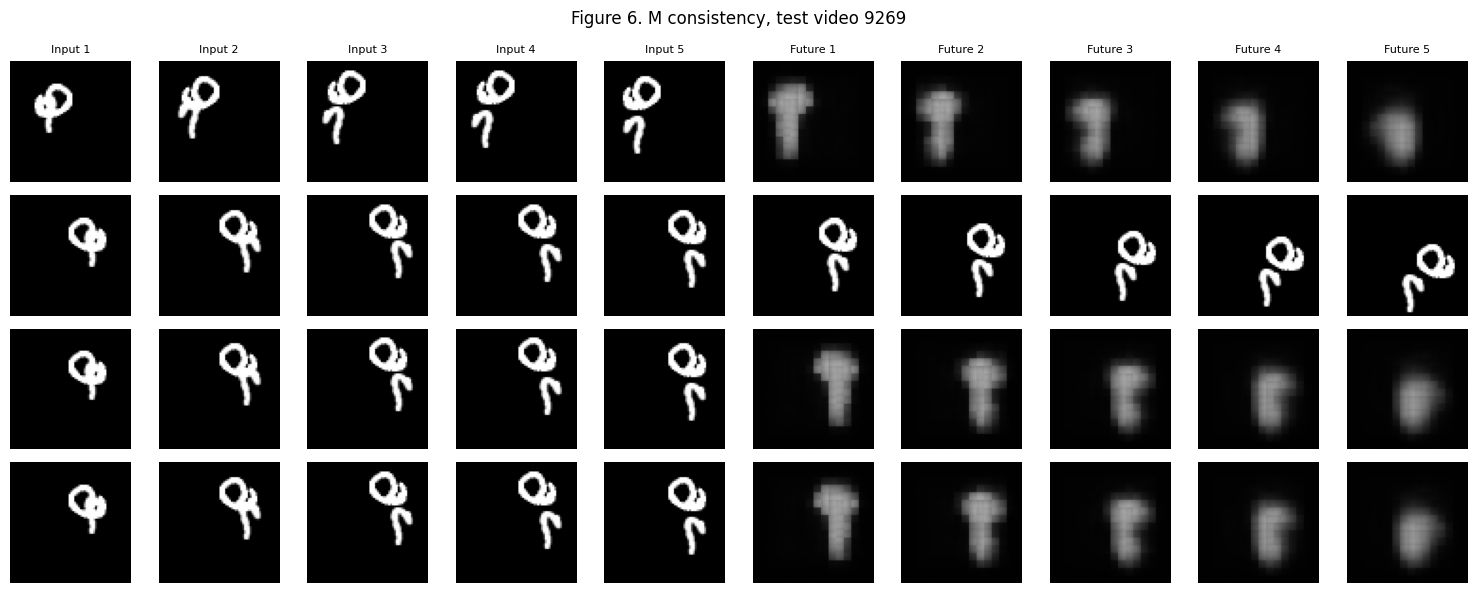

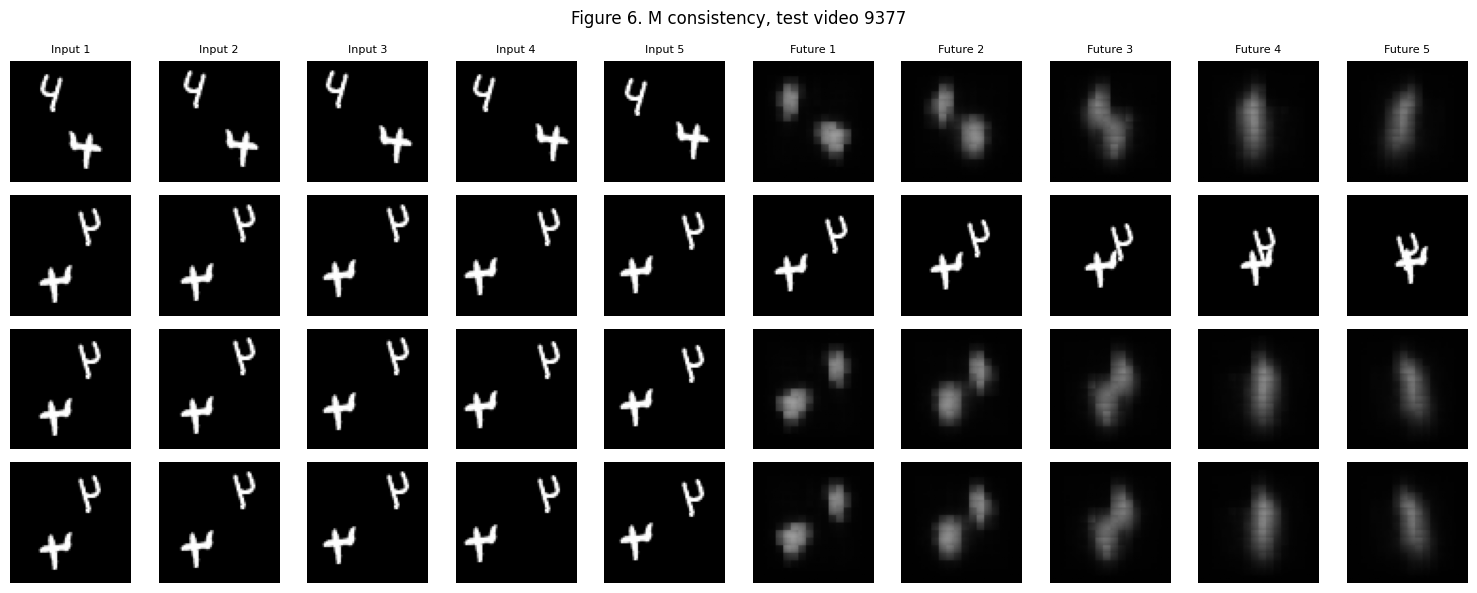

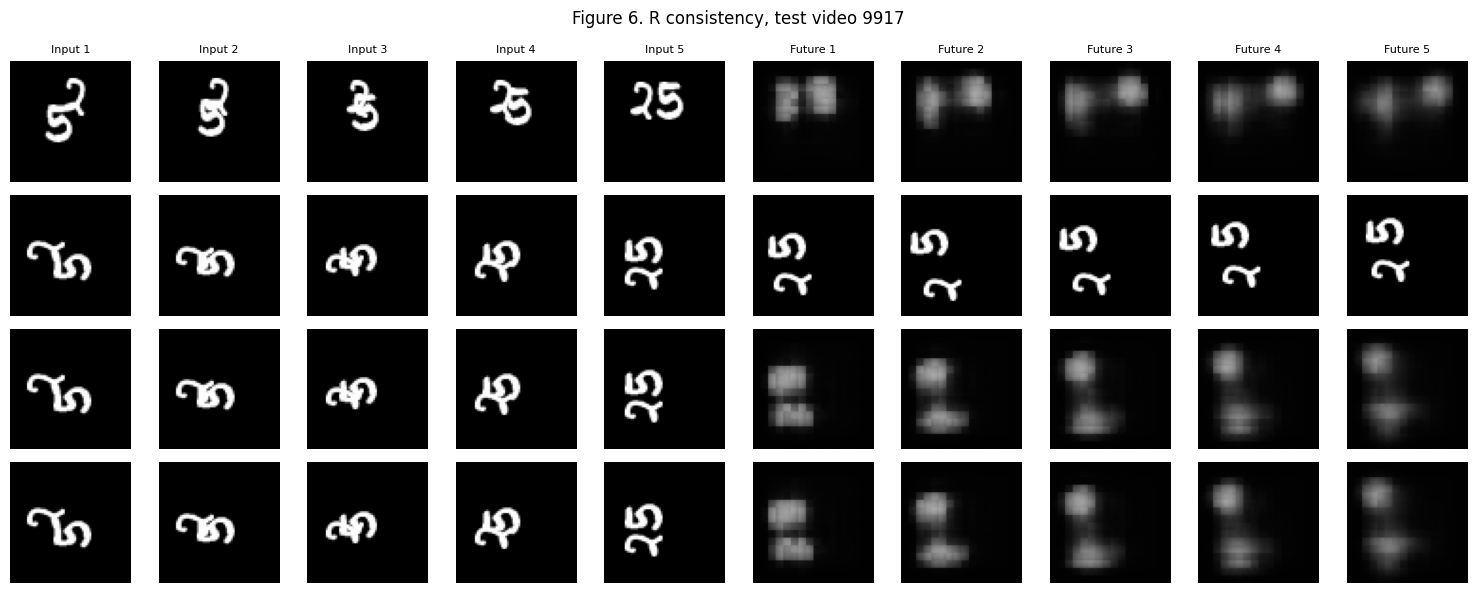

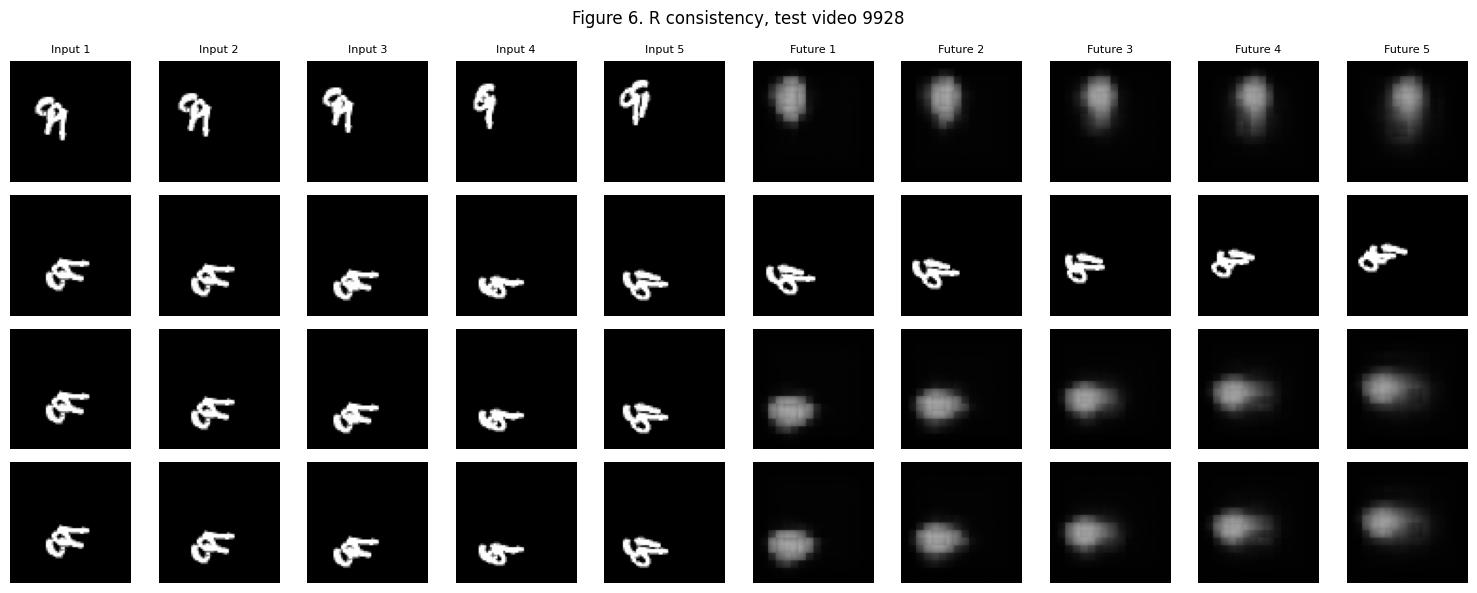

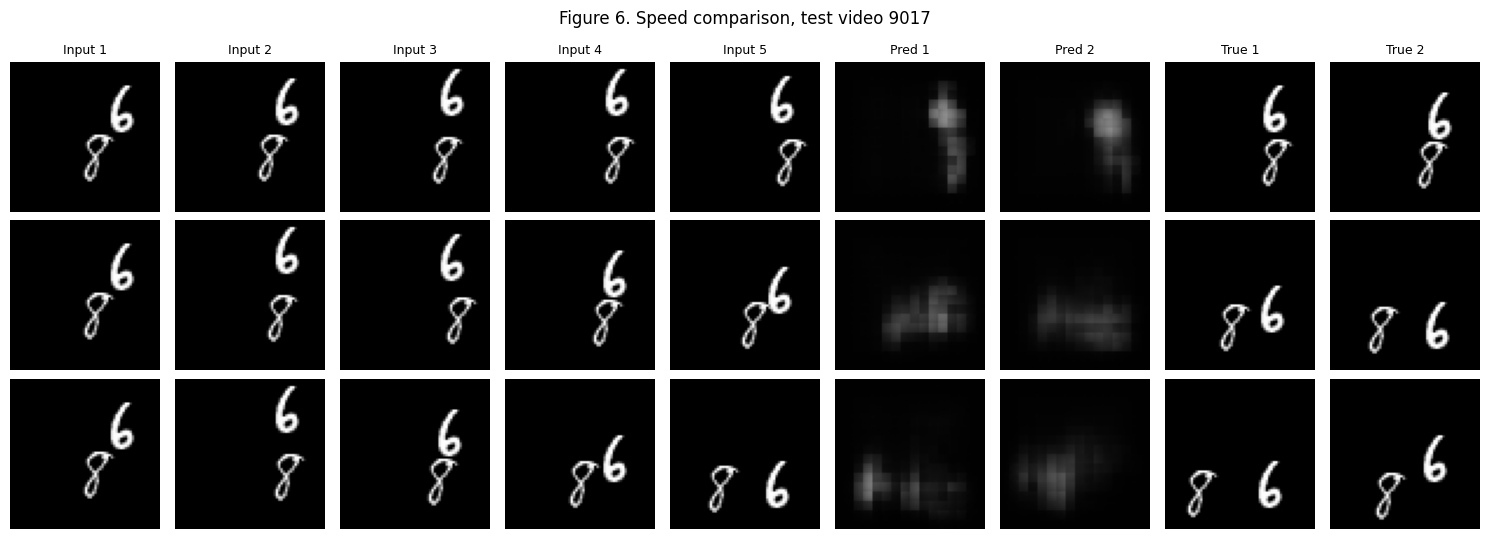

In [10]:
table6_rows = []
for name in ('B', 'D'):
    results = []
    for seed in (0, 1):
        wrapped = Symmetrised(models[name, seed]).to(DEVICE).eval()
        r = model_scores(wrapped)
        r['Training_s_per_epoch'] = times[name, seed]
        results.append(r)
    table6_rows.append({'Model': f'Symmetrised {name}', **two_seeds(*results)})
table6 = save_table(table6_rows, 'table6.csv')

final = Symmetrised(models['D', 0]).to(DEVICE).eval()
make_consistency_panels(final, FIG3_IDS, 6)
speed_panel(final, FIG5_ID, 6)